In [40]:
# ============================================================
# IMPORTS
# ============================================================

import json
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")

In [41]:
# ============================================================
# CONFIG
# ============================================================

PROJECT_DIR = Path(
    r"C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility"
)

DATA_DIR = PROJECT_DIR / "processed_data_final"

OUTPUT_DIR = DATA_DIR / "secondary_safety_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Final asymmetric definition
BRAKE_THRESHOLD = -0.2
ACCEL_THRESHOLD = 0.2

# Critical-event thresholds
STRONG_BRAKE_THRESHOLD = -0.5
SEVERE_BRAKE_THRESHOLD = -1.0

# Error threshold for large mistakes
LARGE_ERROR_THRESHOLD = 0.5

print("Data dir:", DATA_DIR)
print("Output dir:", OUTPUT_DIR)
print("Brake threshold:", BRAKE_THRESHOLD)
print("Accel threshold:", ACCEL_THRESHOLD)

assert DATA_DIR.exists(), f"DATA_DIR does not exist: {DATA_DIR}"

Data dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final
Output dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\secondary_safety_evaluation
Brake threshold: -0.2
Accel threshold: 0.2


In [42]:
# ============================================================
# MANUAL MODEL FILES - SYMMETRIC SECONDARY EVALUATION
# ============================================================

TRANSFORMER_SEQUENCE_TAG = "H25_Hz1_S1"
IDM_FIRST_SEQUENCE_TAG = "H25_S1"
THRESHOLD_TAG = "brake0p2_accel0p2"
IDM_PARAM_TAG = "refinedIDM_v2"

MODEL_FILES = {
    # ========================================================
    # IDM
    # ========================================================
    "Global IDM": (
        DATA_DIR / "idm_core_runs"
        / "idm_core_symmetric_brake0p2_accel0p2"
        / "global_idm_test_predictions.csv"
    ),

    "True-regime IDM": (
        DATA_DIR / "idm_core_runs"
        / "idm_core_symmetric_brake0p2_accel0p2"
        / "oracle_regime_aware_idm_test_predictions.csv"
    ),

    "Ideal best-candidate IDM": (
        DATA_DIR / "idm_core_runs"
        / "idm_core_symmetric_brake0p2_accel0p2"
        / "ideal_best_candidate_idm_test_predictions.csv"
    ),

    "XGB-soft best-IDM selector": (
        DATA_DIR / "idm_selector_comparison_runs"
        / "idm_selector_comparison_symmetric_brake0p2_accel0p2"
        / "xgb_soft_best_idm_test_predictions.csv"
    ),

    # ========================================================
    # IDM-first residual hybrids
    # ========================================================
    "Residual Hybrid + Global IDM": (
        DATA_DIR / "hybrid_idm_first_runs"
        / "Hybrid_GlobalIDM_H25_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "test_predictions.csv"
    ),

    "Residual Hybrid + True-regime IDM": (
        DATA_DIR / "hybrid_idm_first_runs"
        / "Hybrid_OracleRegimeAwareIDM_H25_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "test_predictions.csv"
    ),

    "Residual Hybrid + Tree-selected IDM": (
        DATA_DIR / "hybrid_idm_first_runs"
        / "Hybrid_TreeRegimeAwareIDM_H25_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "test_predictions.csv"
    ),

    "Residual Hybrid + XGB-soft best-IDM": (
        DATA_DIR / "hybrid_idm_first_runs"
        / "Hybrid_XGBSoftBestIDM_H25_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "test_predictions.csv"
    ),

    # ========================================================
    # Transformer-based hybrids
    # ========================================================
    "Transformer Weighted Fusion + Global IDM": (
        DATA_DIR / "transformer_weighted_fusion_runs"
        / "TransformerWeightedFusion_GlobalIDM_H25_Hz1_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "weighted_fusion_test_predictions.csv"
    ),

    "Transformer Weighted Fusion + True-regime IDM": (
        DATA_DIR / "transformer_weighted_fusion_runs"
        / "TransformerWeightedFusion_IdealRegimeAwareIDM_H25_Hz1_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "weighted_fusion_test_predictions.csv"
    ),

    "Transformer Weighted Fusion + Tree-selected IDM": (
        DATA_DIR / "transformer_weighted_fusion_runs"
        / "TransformerWeightedFusion_TreeRegimeAwareIDM_H25_Hz1_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "weighted_fusion_test_predictions.csv"
    ),

    "Transformer + XGB-soft best-IDM feature": (
        DATA_DIR / "transformer_idm_feature_runs"
        / "TransformerIDMFeature_XGBSoftBestIDM_H25_Hz1_S1_brake0p2_accel0p2_refinedIDM_v2"
        / "transformer_xgb_soft_best_idm_feature_test_predictions.csv"
    ),

    # ========================================================
    # Plain Transformer
    # ========================================================
    "Plain Transformer": (
        DATA_DIR / "transformer_baseline_runs"
        / "transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2"
        / "transformer_test_predictions.csv"
    ),
}

# ============================================================
# Validate paths
# ============================================================

missing = []

for model_name, path in MODEL_FILES.items():
    if not path.exists():
        missing.append((model_name, path))

if missing:
    print("\nMissing files:")
    for model_name, path in missing:
        print(f"- {model_name}: {path}")
    raise FileNotFoundError("Some manual symmetric model files are missing.")
else:
    print("\nAll manual symmetric model files exist.")

print("\nFINAL MODEL_FILES USED:")
for model_name, path in MODEL_FILES.items():
    print(f"- {model_name}: {path}")

print("\nTotal models:", len(MODEL_FILES))


All manual symmetric model files exist.

FINAL MODEL_FILES USED:
- Global IDM: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\global_idm_test_predictions.csv
- True-regime IDM: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\oracle_regime_aware_idm_test_predictions.csv
- Ideal best-candidate IDM: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\ideal_best_candidate_idm_test_predictions.csv
- XGB-soft best-IDM selector: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_selector_comparison_runs\idm_selector_comparison_symmetric_brake0p2_accel0p2\xgb_soft_best_idm_test_predictions.csv
- Residual Hybrid + Global IDM: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\hybrid_idm_first_runs\Hyb

In [43]:
# ============================================================
# CHECK DISCOVERED MODELS
# ============================================================

print("=== MODELS DISCOVERED FOR SECONDARY EVALUATION ===")

for i, (model_name, path) in enumerate(MODEL_FILES.items(), start=1):
    print(f"{i:02d}. {model_name}")
    print(f"    {path}")

print("\nTotal models:", len(MODEL_FILES))

=== MODELS DISCOVERED FOR SECONDARY EVALUATION ===
01. Global IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\global_idm_test_predictions.csv
02. True-regime IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\oracle_regime_aware_idm_test_predictions.csv
03. Ideal best-candidate IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_core_runs\idm_core_symmetric_brake0p2_accel0p2\ideal_best_candidate_idm_test_predictions.csv
04. XGB-soft best-IDM selector
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\idm_selector_comparison_runs\idm_selector_comparison_symmetric_brake0p2_accel0p2\xgb_soft_best_idm_test_predictions.csv
05. Residual Hybrid + Global IDM
    C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\hybrid_idm_firs

In [44]:
# ============================================================
# LOAD AVAILABLE MODEL PREDICTIONS
# Memory-safe: only load useful columns
# ============================================================

POSSIBLE_USEFUL_COLS = [
    "y_true", "y_pred",
    "a_true", "target", "true_accel",
    "prediction", "a_pred", "pred", "test_pred", "y_hat",
    "a_idm", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",
    "gap", "v_ego", "v_leader", "delta_v",
    "episode_id", "unique_id", "frame", "split",
]


def load_prediction_file(model_name, path):
    if not path.exists():
        print(f"Missing file for {model_name}:")
        print(path)
        return None

    header = pd.read_csv(path, nrows=0).columns.tolist()
    usecols = [c for c in POSSIBLE_USEFUL_COLS if c in header]

    if len(usecols) == 0:
        print(f"No useful columns found for {model_name}: {path}")
        print("Available columns:", header)
        return None

    dtype_map = {}
    for c in usecols:
        if c in [
            "y_true", "y_pred", "a_true", "target", "true_accel",
            "prediction", "a_pred", "pred", "test_pred", "y_hat",
            "a_idm", "a_idm_piecewise", "a_idm_best_candidate", "a_idm_soft", "a_hybrid",
            "gap", "v_ego", "v_leader", "delta_v",
        ]:
            dtype_map[c] = "float32"
        elif c == "frame":
            dtype_map[c] = "int32"

    df = pd.read_csv(
        path,
        usecols=usecols,
        dtype=dtype_map,
        low_memory=False,
    )

    if "episode_id" in df.columns:
        df["episode_id"] = df["episode_id"].astype("category")

    if "unique_id" in df.columns:
        df["unique_id"] = df["unique_id"].astype("category")

    if "split" in df.columns:
        df["split"] = df["split"].astype("category")

    df["Model"] = model_name
    df["source_file"] = str(path)

    print(f"Loaded {model_name}: {df.shape}")
    return df


model_dfs = {}

for model_name, path in MODEL_FILES.items():
    df = load_prediction_file(model_name, path)

    if df is not None:
        model_dfs[model_name] = df

print("\nLoaded models:")
for name in model_dfs:
    print("-", name)

assert len(model_dfs) > 0, "No model prediction files were loaded."

Loaded Global IDM: (2368174, 12)
Loaded True-regime IDM: (2368174, 12)
Loaded Ideal best-candidate IDM: (2368174, 12)
Loaded XGB-soft best-IDM selector: (2368174, 12)
Loaded Residual Hybrid + Global IDM: (2188870, 9)
Loaded Residual Hybrid + True-regime IDM: (2188870, 9)
Loaded Residual Hybrid + Tree-selected IDM: (2188870, 9)
Loaded Residual Hybrid + XGB-soft best-IDM: (2188870, 9)
Loaded Transformer Weighted Fusion + Global IDM: (2181399, 13)
Loaded Transformer Weighted Fusion + True-regime IDM: (2181399, 13)
Loaded Transformer Weighted Fusion + Tree-selected IDM: (2181399, 13)
Loaded Transformer + XGB-soft best-IDM feature: (2181399, 13)
Loaded Plain Transformer: (2181399, 6)

Loaded models:
- Global IDM
- True-regime IDM
- Ideal best-candidate IDM
- XGB-soft best-IDM selector
- Residual Hybrid + Global IDM
- Residual Hybrid + True-regime IDM
- Residual Hybrid + Tree-selected IDM
- Residual Hybrid + XGB-soft best-IDM
- Transformer Weighted Fusion + Global IDM
- Transformer Weighted 

In [45]:
# ============================================================
# STANDARDIZE PREDICTION COLUMNS
# ============================================================

def standardize_prediction_df(df, model_name):
    # Work with only necessary columns
    out = df.copy()

    # Standardize y_true
    if "y_true" not in out.columns:
        for c in ["a_true", "target", "true_accel"]:
            if c in out.columns:
                out["y_true"] = out[c].astype(np.float32)
                break

    # Standardize y_pred
    if "y_pred" not in out.columns:
        for c in [
            "prediction",
            "a_pred",
            "pred",
            "test_pred",
            "y_hat",
            "a_idm",
            "a_idm_piecewise",
            "a_idm_best_candidate",
            "a_idm_soft",
            "a_hybrid",
        ]:
            if c in out.columns:
                out["y_pred"] = out[c].astype(np.float32)
                break

    if "y_true" not in out.columns or "y_pred" not in out.columns:
        raise ValueError(
            f"{model_name} is missing y_true/y_pred columns. "
            f"Available columns: {list(out.columns)}"
        )

    optional_cols = ["gap", "v_ego", "v_leader", "delta_v", "episode_id", "unique_id", "frame", "split"]

    keep_cols = ["y_true", "y_pred", "Model", "source_file"] + [
        c for c in optional_cols if c in out.columns
    ]

    out = out[keep_cols].copy()

    # Add missing optional columns after trimming
    for c in optional_cols:
        if c not in out.columns:
            out[c] = np.nan

    out["y_true"] = pd.to_numeric(out["y_true"], errors="coerce").astype(np.float32)
    out["y_pred"] = pd.to_numeric(out["y_pred"], errors="coerce").astype(np.float32)

    before = len(out)
    out = out.dropna(subset=["y_true", "y_pred"]).copy()
    after = len(out)

    if after < before:
        print(f"{model_name}: dropped {before - after} rows with missing y_true/y_pred")

    out["error"] = (out["y_pred"] - out["y_true"]).astype(np.float32)
    out["abs_error"] = np.abs(out["error"]).astype(np.float32)

    out["regime"] = np.where(
        out["y_true"] < BRAKE_THRESHOLD,
        "braking",
        np.where(out["y_true"] > ACCEL_THRESHOLD, "accelerating", "steady")
    )

    out["regime"] = pd.Categorical(
        out["regime"],
        categories=["accelerating", "braking", "steady"]
    )

    out["Model"] = model_name

    return out


std_model_dfs = {}

for model_name, df in model_dfs.items():
    try:
        std_model_dfs[model_name] = standardize_prediction_df(df, model_name)
    except Exception as e:
        print(f"Skipping {model_name} due to error:")
        print(e)

# Free raw loaded prediction dataframes
del model_dfs
gc.collect()

all_preds = pd.concat(std_model_dfs.values(), ignore_index=True)

print("Combined predictions:", all_preds.shape)
print("\nModels included:")
print(all_preds["Model"].value_counts())

print("\nPreview:")
print(all_preds[["Model", "y_true", "y_pred", "error", "regime"]].head())

Combined predictions: (29135171, 15)

Models included:
Model
Global IDM                                         2368174
True-regime IDM                                    2368174
Ideal best-candidate IDM                           2368174
XGB-soft best-IDM selector                         2368174
Residual Hybrid + Global IDM                       2188870
Residual Hybrid + True-regime IDM                  2188870
Residual Hybrid + Tree-selected IDM                2188870
Residual Hybrid + XGB-soft best-IDM                2188870
Transformer Weighted Fusion + Global IDM           2181399
Transformer Weighted Fusion + True-regime IDM      2181399
Transformer Weighted Fusion + Tree-selected IDM    2181399
Transformer + XGB-soft best-IDM feature            2181399
Plain Transformer                                  2181399
Name: count, dtype: int64

Preview:
        Model  y_true    y_pred     error  regime
0  Global IDM    0.17  0.299877  0.129877  steady
1  Global IDM    0.17  0.299772  0.1

In [46]:
# ============================================================
# METRIC HELPERS
# ============================================================

def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    corr = np.nan
    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        corr = float(np.corrcoef(y_true, y_pred)[0, 1])

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedAE": median_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Bias": float(np.mean(y_pred - y_true)),
        "Corr": corr,
    }


def metric_table_by_model(df):
    rows = []

    for model_name, g in df.groupby("Model"):
        m = compute_metrics(g["y_true"], g["y_pred"])
        m["Model"] = model_name
        m["Count"] = len(g)
        rows.append(m)

    return pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)


def metric_table_by_model_and_regime(df):
    rows = []

    for (model_name, regime), g in df.groupby(["Model", "regime"]):
        m = compute_metrics(g["y_true"], g["y_pred"])
        m["Model"] = model_name
        m["Regime"] = regime
        m["Count"] = len(g)
        rows.append(m)

    out = pd.DataFrame(rows)

    regime_order = ["accelerating", "braking", "steady"]
    out["Regime"] = pd.Categorical(out["Regime"], categories=regime_order, ordered=True)

    return out.sort_values(["Regime", "MAE"]).reset_index(drop=True)

In [47]:
# ============================================================
# GLOBAL AND REGIME METRICS
# ============================================================

global_metrics_df = metric_table_by_model(all_preds)
regime_metrics_df = metric_table_by_model_and_regime(all_preds)

print("=== GLOBAL METRICS ===")
print(global_metrics_df[["Model", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr", "Count"]].to_string(index=False))

print("\n=== REGIME METRICS ===")
print(regime_metrics_df[["Model", "Regime", "MAE", "RMSE", "Bias", "Count"]].to_string(index=False))

=== GLOBAL METRICS ===
                                          Model      MAE     RMSE    MedAE        R2      Bias      Corr   Count
              Residual Hybrid + True-regime IDM 0.106656 0.151321 0.082898  0.787685 -0.025238  0.891963 2188870
                       Ideal best-candidate IDM 0.108056 0.195589 0.069797  0.637827 -0.006277  0.804899 2368174
  Transformer Weighted Fusion + True-regime IDM 0.113325 0.205625 0.068460  0.608385 -0.004725  0.816770 2181399
                                True-regime IDM 0.129256 0.214151 0.092586  0.565826  0.001369  0.753399 2368174
                              Plain Transformer 0.143432 0.265859 0.071500  0.345347 -0.002777  0.589217 2181399
       Transformer Weighted Fusion + Global IDM 0.145482 0.267054 0.074656  0.339449 -0.009022  0.584467 2181399
Transformer Weighted Fusion + Tree-selected IDM 0.146479 0.268111 0.077364  0.334206 -0.012749  0.584300 2181399
        Transformer + XGB-soft best-IDM feature 0.148338 0.268491 0.07758

In [48]:
# ============================================================
# ERROR TAIL / LARGE-ERROR ANALYSIS
# ============================================================

tail_rows = []

for model_name, g in all_preds.groupby("Model"):
    abs_err = g["abs_error"].values

    tail_rows.append({
        "Model": model_name,
        "P50_abs_error": np.percentile(abs_err, 50),
        "P75_abs_error": np.percentile(abs_err, 75),
        "P90_abs_error": np.percentile(abs_err, 90),
        "P95_abs_error": np.percentile(abs_err, 95),
        "P99_abs_error": np.percentile(abs_err, 99),
        "LargeErrorRate_abs_gt_0p5": np.mean(abs_err > LARGE_ERROR_THRESHOLD),
        "Max_abs_error": np.max(abs_err),
        "Count": len(g)
    })

tail_metrics_df = pd.DataFrame(tail_rows).sort_values("P95_abs_error").reset_index(drop=True)

print("=== ERROR TAIL METRICS ===")
print(tail_metrics_df.to_string(index=False))

=== ERROR TAIL METRICS ===
                                          Model  P50_abs_error  P75_abs_error  P90_abs_error  P95_abs_error  P99_abs_error  LargeErrorRate_abs_gt_0p5  Max_abs_error   Count
              Residual Hybrid + True-regime IDM       0.082898       0.143029       0.203665       0.272745       0.521013                   0.011166       7.055747 2188870
                       Ideal best-candidate IDM       0.069797       0.123746       0.193267       0.330045       0.838612                   0.027652       3.829594 2368174
  Transformer Weighted Fusion + True-regime IDM       0.068460       0.127608       0.232678       0.359372       0.881692                   0.029299       6.686748 2181399
                                True-regime IDM       0.092586       0.155788       0.239617       0.360887       0.863206                   0.030279       7.305130 2368174
                              Plain Transformer       0.071500       0.159656       0.338655       0.518754 

In [49]:
# ============================================================
# BRAKING SAFETY ANALYSIS
# ============================================================

def braking_safety_metrics(df):
    rows = []

    for model_name, g_all in df.groupby("Model"):
        g = g_all[g_all["y_true"] < BRAKE_THRESHOLD].copy()

        if len(g) == 0:
            continue

        # Under-braking: prediction is less negative than true braking
        # Example: true -1.0, pred -0.2 => under-braking error +0.8
        under_brake_error = g["y_pred"] - g["y_true"]

        rows.append({
            "Model": model_name,
            "Braking_Count": len(g),
            "Braking_MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
            "Braking_RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
            "Braking_Bias": np.mean(g["y_pred"] - g["y_true"]),

            # Safety-specific
            "UnderBrake_Mean": np.mean(np.maximum(under_brake_error, 0)),
            "UnderBrake_P95": np.percentile(np.maximum(under_brake_error, 0), 95),
            "UnderBrake_Rate_gt_0p2": np.mean(under_brake_error > 0.2),
            "UnderBrake_Rate_gt_0p5": np.mean(under_brake_error > 0.5),
            "WrongSign_Rate_in_Braking": np.mean(g["y_pred"] > 0.0),
            "Predicts_SteadyOrAccel_Rate": np.mean(g["y_pred"] > BRAKE_THRESHOLD),
        })

    return pd.DataFrame(rows).sort_values("UnderBrake_Rate_gt_0p5").reset_index(drop=True)


braking_safety_df = braking_safety_metrics(all_preds)

print("=== BRAKING SAFETY METRICS ===")
print(braking_safety_df.to_string(index=False))

=== BRAKING SAFETY METRICS ===
                                          Model  Braking_Count  Braking_MAE  Braking_RMSE  Braking_Bias  UnderBrake_Mean  UnderBrake_P95  UnderBrake_Rate_gt_0p2  UnderBrake_Rate_gt_0p5  WrongSign_Rate_in_Braking  Predicts_SteadyOrAccel_Rate
              Residual Hybrid + True-regime IDM         264917     0.174170      0.252140     -0.021967         0.076102        0.442381                0.132275                0.040428                   0.000736                     0.013102
                       Ideal best-candidate IDM         284097     0.202152      0.323151      0.136568         0.169360        0.699826                0.282108                0.099473                   0.003119                     0.201882
                                True-regime IDM         284097     0.220635      0.348660      0.119684         0.170159        0.715822                0.284720                0.103623                   0.001038                     0.169104
  Tra

In [50]:
# ============================================================
# SEVERE BRAKING SUBSET
# ============================================================

severe_rows = []

for model_name, g_all in all_preds.groupby("Model"):
    g = g_all[g_all["y_true"] < SEVERE_BRAKE_THRESHOLD].copy()

    if len(g) == 0:
        continue

    under_brake_error = g["y_pred"] - g["y_true"]

    severe_rows.append({
        "Model": model_name,
        "SevereBraking_Count": len(g),
        "MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
        "RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
        "Bias": np.mean(g["y_pred"] - g["y_true"]),
        "UnderBrake_Mean": np.mean(np.maximum(under_brake_error, 0)),
        "UnderBrake_P95": np.percentile(np.maximum(under_brake_error, 0), 95),
        "WrongSign_Rate": np.mean(g["y_pred"] > 0.0),
        "Pred_NotSevereBrake_Rate": np.mean(g["y_pred"] > SEVERE_BRAKE_THRESHOLD),
    })

severe_braking_df = pd.DataFrame(severe_rows).sort_values("MAE").reset_index(drop=True)

print("=== SEVERE BRAKING SUBSET METRICS ===")
print(severe_braking_df.to_string(index=False))

=== SEVERE BRAKING SUBSET METRICS ===
                                          Model  SevereBraking_Count      MAE     RMSE     Bias  UnderBrake_Mean  UnderBrake_P95  WrongSign_Rate  Pred_NotSevereBrake_Rate
              Residual Hybrid + True-regime IDM                13735 0.625958 0.741698 0.609075         0.617516        1.167733        0.001747                  0.774154
                       Ideal best-candidate IDM                14169 0.932991 1.040114 0.903745         0.918368        1.798027        0.001129                  0.856094
                                True-regime IDM                14169 1.037725 1.144303 1.028546         1.033136        1.966727        0.001129                  0.967182
  Transformer Weighted Fusion + True-regime IDM                13710 1.123088 1.257416 1.122298         1.122693        2.307822        0.100875                  0.977170
        Transformer + XGB-soft best-IDM feature                13710 1.226118 1.504991 1.208651         1.2

In [51]:
# ============================================================
# SIGN / REGIME CONSISTENCY ANALYSIS
# ============================================================

def sign_class(a):
    return np.where(
        a < BRAKE_THRESHOLD,
        "braking",
        np.where(a > ACCEL_THRESHOLD, "accelerating", "steady")
    )


sign_rows = []

for model_name, g in all_preds.groupby("Model"):
    true_sign = sign_class(g["y_true"].values)
    pred_sign = sign_class(g["y_pred"].values)

    braking_mask = true_sign == "braking"
    accel_mask = true_sign == "accelerating"
    steady_mask = true_sign == "steady"

    sign_rows.append({
        "Model": model_name,
        "SignAccuracy": np.mean(true_sign == pred_sign),
        "BrakeRecall": np.mean(pred_sign[braking_mask] == "braking") if braking_mask.any() else np.nan,
        "AccelRecall": np.mean(pred_sign[accel_mask] == "accelerating") if accel_mask.any() else np.nan,
        "SteadyRecall": np.mean(pred_sign[steady_mask] == "steady") if steady_mask.any() else np.nan,
        "BrakeAsAccelRate": np.mean(pred_sign[braking_mask] == "accelerating") if braking_mask.any() else np.nan,
        "AccelAsBrakeRate": np.mean(pred_sign[accel_mask] == "braking") if accel_mask.any() else np.nan,
    })

sign_metrics_df = (
    pd.DataFrame(sign_rows)
    .sort_values("SignAccuracy", ascending=False)
    .reset_index(drop=True)
)

print("=== SIGN / REGIME CONSISTENCY METRICS ===")
print(sign_metrics_df.to_string(index=False))

=== SIGN / REGIME CONSISTENCY METRICS ===
                                          Model  SignAccuracy  BrakeRecall  AccelRecall  SteadyRecall  BrakeAsAccelRate  AccelAsBrakeRate
              Residual Hybrid + True-regime IDM      0.997247     0.986898     0.998945      0.998541          0.000381          0.000000
                                True-regime IDM      0.967261     0.830896     0.985500      0.986017          0.000000          0.000976
  Transformer Weighted Fusion + True-regime IDM      0.923819     0.507416     0.952134      0.995228          0.002123          0.000846
                       Ideal best-candidate IDM      0.876732     0.798118     0.915153      0.874254          0.000000          0.000976
                              Plain Transformer      0.764218     0.268788     0.506461      0.989745          0.165658          0.011702
       Transformer Weighted Fusion + Global IDM      0.763568     0.279068     0.502083      0.988660          0.168008          0

In [52]:
# ============================================================
# CRITICAL SITUATION ANALYSIS — MEMORY SAFE BY MODEL
# ============================================================

critical_rows = []

required_critical_cols = ["gap", "delta_v", "v_ego"]

for model_name, df in std_model_dfs.items():
    missing_cols = [c for c in required_critical_cols if c not in df.columns]

    if missing_cols:
        print(f"Skipping critical analysis for {model_name}: missing {missing_cols}")
        continue

    needed_cols = ["y_true", "y_pred", "gap", "delta_v", "v_ego"]
    g_all = df[needed_cols].dropna(subset=needed_cols).copy()

    if len(g_all) == 0:
        continue

    g_all["closing_speed"] = np.maximum(g_all["delta_v"], 0.0)
    g_all["inv_ttc"] = g_all["closing_speed"] / np.maximum(g_all["gap"], 0.1)
    g_all["time_headway"] = g_all["gap"] / np.maximum(g_all["v_ego"], 0.1)

    masks = {
        "CloseFollowing": (
            (g_all["gap"] < 15.0)
            & (g_all["closing_speed"] > 1.0)
        ),
        "HighInvTTC": g_all["inv_ttc"] > 0.25,
        "LowHeadway": g_all["time_headway"] < 1.0,
    }

    for subset_name, mask in masks.items():
        g = g_all.loc[mask]

        if len(g) == 0:
            continue

        under_brake_error = g["y_pred"] - g["y_true"]

        critical_rows.append({
            "Model": model_name,
            "Subset": subset_name,
            "Count": len(g),
            "MAE": mean_absolute_error(g["y_true"], g["y_pred"]),
            "RMSE": np.sqrt(mean_squared_error(g["y_true"], g["y_pred"])),
            "Bias": np.mean(g["y_pred"] - g["y_true"]),
            "UnderBrake_Rate_gt_0p5": np.mean(under_brake_error > 0.5),
            "WrongSign_Rate": np.mean(np.sign(g["y_true"]) != np.sign(g["y_pred"])),
        })

if len(critical_rows) == 0:
    print("No critical-condition rows were found.")
    critical_metrics_df = pd.DataFrame(columns=[
        "Model", "Subset", "Count", "MAE", "RMSE", "Bias",
        "UnderBrake_Rate_gt_0p5", "WrongSign_Rate"
    ])
else:
    critical_metrics_df = (
        pd.DataFrame(critical_rows)
        .sort_values(["Subset", "MAE"])
        .reset_index(drop=True)
    )

    print("=== CRITICAL SITUATION METRICS ===")
    print(critical_metrics_df.to_string(index=False))

=== CRITICAL SITUATION METRICS ===
                                          Model         Subset  Count      MAE     RMSE      Bias  UnderBrake_Rate_gt_0p5  WrongSign_Rate
        Transformer + XGB-soft best-IDM feature CloseFollowing  15003 0.405315 0.719421  0.073611                0.153503        0.211424
  Transformer Weighted Fusion + True-regime IDM CloseFollowing  14991 0.429875 0.703018 -0.126366                0.094056        0.080849
       Transformer Weighted Fusion + Global IDM CloseFollowing  14991 0.442831 0.785917  0.057934                0.159029        0.223668
                       Ideal best-candidate IDM CloseFollowing  15589 0.447483 0.711685 -0.256503                0.053499        0.064020
Transformer Weighted Fusion + Tree-selected IDM CloseFollowing  14991 0.448219 0.799680  0.114416                0.184778        0.223267
                                True-regime IDM CloseFollowing  15589 0.521242 0.788570 -0.299525                0.068382        0.067997

In [53]:
# ============================================================
# FINAL SAFETY SUMMARY TABLE
# ============================================================

safety_summary_df = (
    global_metrics_df[["Model", "MAE", "RMSE", "MedAE", "R2", "Bias", "Corr"]]
    .merge(
        tail_metrics_df[["Model", "P95_abs_error", "P99_abs_error", "LargeErrorRate_abs_gt_0p5"]],
        on="Model",
        how="left"
    )
    .merge(
        braking_safety_df[[
            "Model",
            "Braking_MAE",
            "UnderBrake_Rate_gt_0p5",
            "WrongSign_Rate_in_Braking",
            "Predicts_SteadyOrAccel_Rate"
        ]],
        on="Model",
        how="left"
    )
    .merge(
        sign_metrics_df[[
            "Model",
            "SignAccuracy",
            "BrakeRecall",
            "AccelRecall",
            "SteadyRecall"
        ]],
        on="Model",
        how="left"
    )
)

# Auxiliary diagnostic score: lower is better.
# This is used only to summarize several safety-oriented indicators together.
# It should not be interpreted as a formal safety guarantee.
safety_summary_df["SafetyRankScore"] = (
    safety_summary_df["MAE"].rank()
    + safety_summary_df["P95_abs_error"].rank()
    + safety_summary_df["UnderBrake_Rate_gt_0p5"].rank()
    + safety_summary_df["WrongSign_Rate_in_Braking"].rank()
    - safety_summary_df["BrakeRecall"].rank()
)

safety_summary_df = safety_summary_df.sort_values("SafetyRankScore").reset_index(drop=True)

print("=== FINAL SAFETY SUMMARY ===")
print(safety_summary_df.to_string(index=False))

=== FINAL SAFETY SUMMARY ===
                                          Model      MAE     RMSE    MedAE        R2      Bias      Corr  P95_abs_error  P99_abs_error  LargeErrorRate_abs_gt_0p5  Braking_MAE  UnderBrake_Rate_gt_0p5  WrongSign_Rate_in_Braking  Predicts_SteadyOrAccel_Rate  SignAccuracy  BrakeRecall  AccelRecall  SteadyRecall  SafetyRankScore
              Residual Hybrid + True-regime IDM 0.106656 0.151321 0.082898  0.787685 -0.025238  0.891963       0.272745       0.521013                   0.011166     0.174170                0.040428                   0.000736                     0.013102      0.997247     0.986898     0.998945      0.998541             -9.0
                       Ideal best-candidate IDM 0.108056 0.195589 0.069797  0.637827 -0.006277  0.804899       0.330045       0.838612                   0.027652     0.202152                0.099473                   0.003119                     0.201882      0.876732     0.798118     0.915153      0.874254           

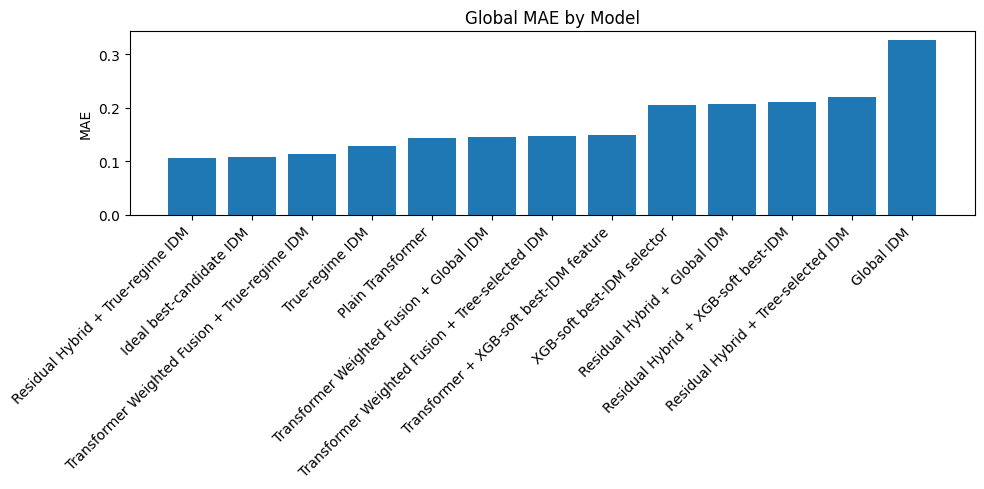

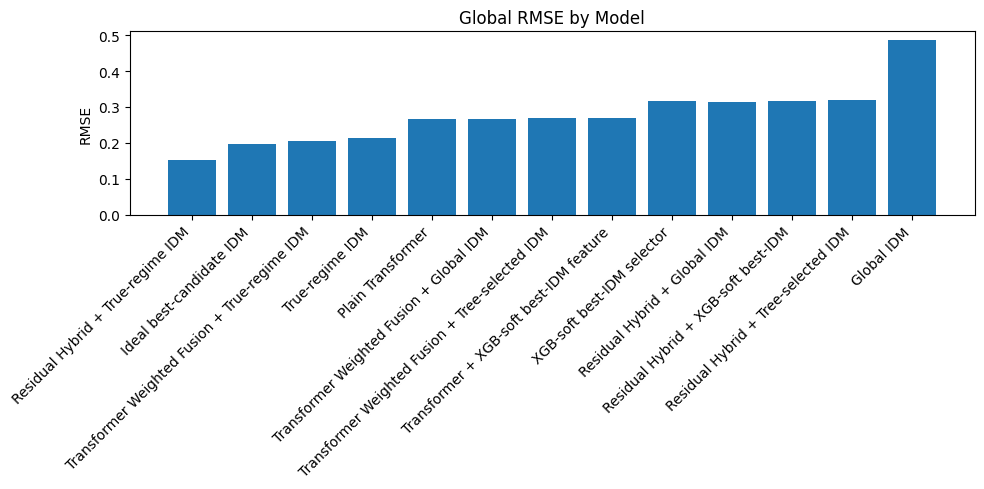

In [54]:
# ============================================================
# PLOT: GLOBAL MAE AND RMSE
# ============================================================

plot_df = global_metrics_df.sort_values("MAE")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["MAE"])
ax.set_title("Global MAE by Model")
ax.set_ylabel("MAE")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_global_mae.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["RMSE"])
ax.set_title("Global RMSE by Model")
ax.set_ylabel("RMSE")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_global_rmse.png", dpi=300)
plt.show()

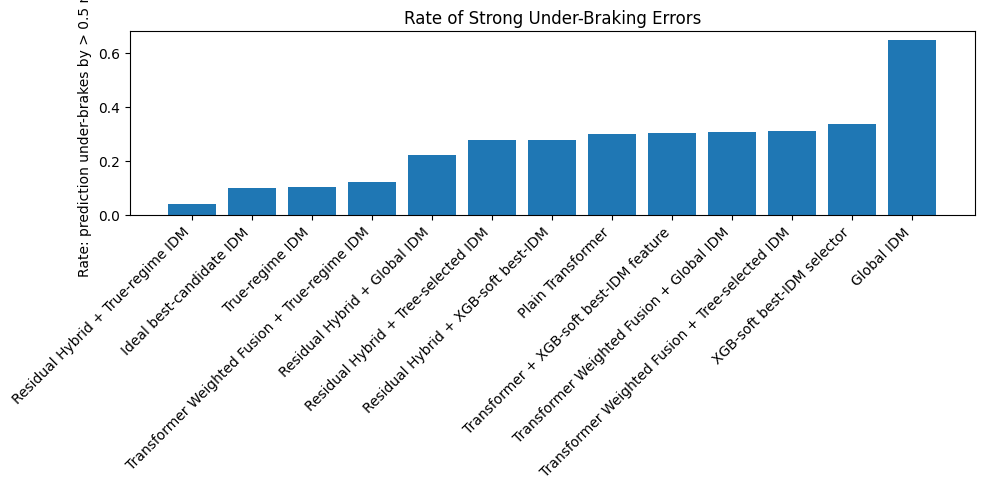

In [55]:
# ============================================================
# PLOT: BRAKING UNDERPREDICTION RATE
# ============================================================

plot_df = braking_safety_df.sort_values("UnderBrake_Rate_gt_0p5")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["UnderBrake_Rate_gt_0p5"])
ax.set_title("Rate of Strong Under-Braking Errors")
ax.set_ylabel("Rate: prediction under-brakes by > 0.5 m/s²")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Model"], rotation=45, ha="right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "plot_underbraking_rate.png", dpi=300)
plt.show()

In [56]:
# ============================================================
# REGIME MAE TABLE FOR EXPORT
# ============================================================

regime_mae_pivot = regime_metrics_df.pivot(
    index="Model",
    columns="Regime",
    values="MAE"
).reset_index()

print("=== REGIME MAE PIVOT ===")
print(regime_mae_pivot.to_string(index=False))

=== REGIME MAE PIVOT ===
                                          Model  accelerating  braking   steady
                                     Global IDM      0.370059 0.657255 0.239594
                       Ideal best-candidate IDM      0.145086 0.202152 0.071485
                              Plain Transformer      0.189335 0.423877 0.064001
                   Residual Hybrid + Global IDM      0.362333 0.403328 0.092826
            Residual Hybrid + Tree-selected IDM      0.333497 0.421144 0.123036
              Residual Hybrid + True-regime IDM      0.122211 0.174170 0.085378
            Residual Hybrid + XGB-soft best-IDM      0.347579 0.438051 0.098574
        Transformer + XGB-soft best-IDM feature      0.208295 0.425611 0.062778
       Transformer Weighted Fusion + Global IDM      0.198968 0.426364 0.062306
Transformer Weighted Fusion + Tree-selected IDM      0.192426 0.438642 0.064634
  Transformer Weighted Fusion + True-regime IDM      0.138342 0.246190 0.074117
               

In [57]:
# ============================================================
# SAVE OUTPUTS
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_tag = f"{SEQUENCE_TAG}_{THRESHOLD_TAG}_{IDM_PARAM_TAG}"

global_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_global_metrics_{output_tag}.csv",
    index=False
)

regime_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_regime_metrics_{output_tag}.csv",
    index=False
)

tail_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_tail_metrics_{output_tag}.csv",
    index=False
)

braking_safety_df.to_csv(
    OUTPUT_DIR / f"secondary_braking_safety_metrics_{output_tag}.csv",
    index=False
)

severe_braking_df.to_csv(
    OUTPUT_DIR / f"secondary_severe_braking_metrics_{output_tag}.csv",
    index=False
)

sign_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_sign_consistency_metrics_{output_tag}.csv",
    index=False
)

critical_metrics_df.to_csv(
    OUTPUT_DIR / f"secondary_critical_situation_metrics_{output_tag}.csv",
    index=False
)

safety_summary_df.to_csv(
    OUTPUT_DIR / f"secondary_final_safety_summary_{output_tag}.csv",
    index=False
)

regime_mae_pivot.to_csv(
    OUTPUT_DIR / f"secondary_regime_mae_pivot_{output_tag}.csv",
    index=False
)

with open(OUTPUT_DIR / f"secondary_config_{output_tag}.json", "w") as f:
    json.dump({
        "SEQUENCE_TAG": SEQUENCE_TAG,
        "THRESHOLD_TAG": THRESHOLD_TAG,
        "IDM_PARAM_TAG": IDM_PARAM_TAG,
        "BRAKE_THRESHOLD": BRAKE_THRESHOLD,
        "ACCEL_THRESHOLD": ACCEL_THRESHOLD,
        "STRONG_BRAKE_THRESHOLD": STRONG_BRAKE_THRESHOLD,
        "SEVERE_BRAKE_THRESHOLD": SEVERE_BRAKE_THRESHOLD,
        "LARGE_ERROR_THRESHOLD": LARGE_ERROR_THRESHOLD,
        "models_loaded": list(std_model_dfs.keys())
    }, f, indent=2)

print("Saved secondary evaluation outputs to:")
print(OUTPUT_DIR)
print("Output tag:", output_tag)

Saved secondary evaluation outputs to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\secondary_safety_evaluation
Output tag: H25_Hz1_S1_brake0p2_accel0p2_refinedIDM_v2
